In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

Saved 100 training trajectories to: gpr_training_data.csv
Saved single test trajectory to: oscillator_data.csv


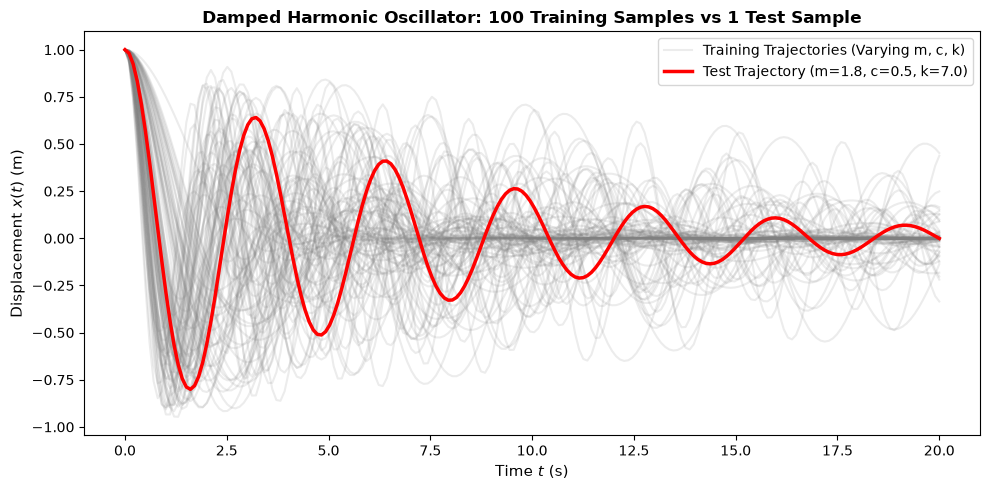

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def damped_oscillator_sim(mass, damping_coeff, spring_const, t_max=20.0, num_points=200):
    def eqns(t, y):
        x, v = y
        return [v, -(damping_coeff / mass) * v - (spring_const / mass) * x]

    y_0 = [1.0, 0.0]
    t_range = np.linspace(0, t_max, num_points)
    sol = solve_ivp(eqns, [0, t_max], y_0, t_eval=t_range)

    x = sol.y[0]
    v = sol.y[1]
    a = -(damping_coeff / mass) * v - (spring_const / mass) * x

    return pd.DataFrame({'t': sol.t, 'x': x, 'v': v, 'a': a})

# --- Generate GPR Training Dataset ---
np.random.seed(42)
num_samples = 100
t_max = 20.0
num_points = 200

training_rows = []
for i in range(num_samples):
    m = np.random.uniform(0.5, 2.0)
    c = np.random.uniform(0.1, 1.0)
    k = np.random.uniform(1.0, 10.0)

    df_sim = damped_oscillator_sim(m, c, k, t_max=t_max, num_points=num_points)
    
    # Store parameters [m, c, k] followed by the 200 displacement values [x_0, ... x_199]
    row = [m, c, k] + df_sim['x'].tolist()
    training_rows.append(row)

# Save training data
col_names = ['mass', 'damping', 'spring'] + [f'x_{i}' for i in range(num_points)]
df_train = pd.DataFrame(training_rows, columns=col_names)
df_train.to_csv('gpr_training_data.csv', index=False)
print("Saved 100 training trajectories to: gpr_training_data.csv")

# --- Generate Single Test/True Dataset for PySR, PINN, and Plotting ---
test_m, test_c, test_k = 1.8, 0.5, 7.0
df_test = damped_oscillator_sim(test_m, test_c, test_k, t_max=t_max, num_points=num_points)
df_test.to_csv('oscillator_data.csv', index=False)
print("Saved single test trajectory to: oscillator_data.csv")

# --- Visualization of Generated Data ---
plt.figure(figsize=(10, 5))
t_plot = df_test['t'].values
y_train = df_train.drop(columns=['mass', 'damping', 'spring']).values

# Plot all 100 training trajectories with low opacity
for i in range(num_samples):
    # Only label the first one to avoid cluttering the legend
    label = 'Training Trajectories (Varying m, c, k)' if i == 0 else None
    plt.plot(t_plot, y_train[i], color='gray', alpha=0.15, label=label)

# Plot the single test trajectory on top
plt.plot(t_plot, df_test['x'], color='red', linewidth=2.5, 
         label=f'Test Trajectory (m={test_m}, c={test_c}, k={test_k})')

plt.title('Damped Harmonic Oscillator: 100 Training Samples vs 1 Test Sample', fontsize=12, fontweight='bold')
plt.xlabel('Time $t$ (s)', fontsize=11)
plt.ylabel('Displacement $x(t)$ (m)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()